# Convergence du Newton au point matériel

On impose $\varepsilon_{11}$ et on cherche les autres composantes de $\boldsymbol{\varepsilon}$ telles que les contraintes correspondantes soient nulles. Le résidu est $\mathbf{r} = \boldsymbol{\sigma}_{\text{libre}}$ ; on compare la tangente cohérente (obtenue par AD) et la tangente élastique.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', 'src')))
import numpy as np, matplotlib.pyplot as plt
import j2gauss                      # active jax_enable_x64
from j2gauss import Params
from j2gauss.driver import run_mixed, UNIAXIAL, TENSION_SHEAR
%matplotlib inline

In [2]:
def uni(e11):
    p = np.zeros((len(e11), 6)); p[:, 0] = e11
    return p

voce = Params(Q=150., b=50.)
lin = Params()
cases = {
  'Voce, cohérente': run_mixed(uni([1e-3, 6e-3]), UNIAXIAL, voce, 'consistent', tol=1e-11),
  'Voce, élastique': run_mixed(uni([1e-3, 6e-3]), UNIAXIAL, voce, 'elastic', tol=1e-11),
  'Linéaire, cohérente': run_mixed(uni([1e-3, 6e-3]), UNIAXIAL, lin, 'consistent', tol=1e-11),
}
for k, r in cases.items():
    print(f'{k:22s}', ['%.1e' % x for x in r['residuals'][1]])

Voce, cohérente        ['1.2e+03', '1.8e-01', '3.6e-09', '6.3e-14']
Voce, élastique        ['1.2e+03', '1.6e+02', '2.0e+01', '2.6e+00', '3.4e-01', '4.4e-02', '5.7e-03', '7.4e-04', '9.6e-05', '1.2e-05', '1.6e-06', '2.1e-07', '2.7e-08', '3.5e-09', '4.6e-10', '5.9e-11', '7.8e-12']
Linéaire, cohérente    ['1.2e+03', '9.4e-14']


Avec la tangente cohérente le nombre de chiffres exacts double à chaque itération (convergence quadratique). Avec la tangente élastique le résidu est multiplié par un facteur constant (convergence linéaire). Avec l'écrouissage **linéaire** en chargement proportionnel, la réponse $\sigma_{22}(\varepsilon_{22})$ est affine par morceaux : Newton converge en **une** itération, on ne peut pas y voir la convergence quadratique.

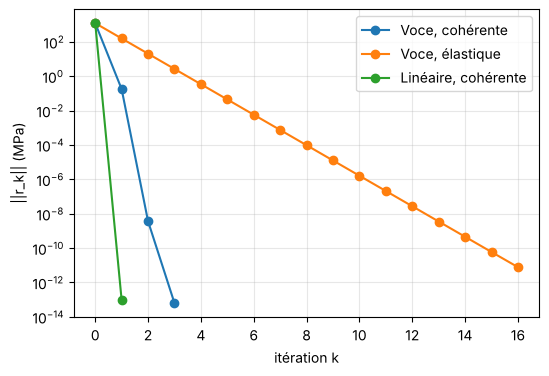

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
for k, r in cases.items():
    h = np.maximum(r['residuals'][1], 1e-16)
    ax.semilogy(h, 'o-', label=k)
ax.set_xlabel('itération k'); ax.set_ylabel('||r_k|| (MPa)'); ax.legend(); ax.grid(alpha=.3)

In [4]:
r = np.array(cases['Voce, cohérente']['residuals'][1])
print('ordre empirique :', np.log(r[2]/r[1]) / np.log(r[1]/r[0]))

ordre empirique : 2.005450626201617
